In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv('../data/cleaned_data.csv', low_memory=False)

df['Date'] = pd.to_datetime(df['Date'])

print(f"Dataset loaded successfully!")
print(f"Shape: {df.shape}")
print(f"Date range: {df['Date'].min()} to {df['Date'].max()}")

Dataset loaded successfully!
Shape: (1017155, 18)
Date range: 2013-01-01 00:00:00 to 2015-07-31 00:00:00


In [4]:
import os
print(os.getcwd())

C:\Users\USER-PC\OneDrive\Desktop\retail_forecasting\notebooks


In [9]:
print("Columns:", df.columns.tolist())
print("\nFIRST 5 ROWS:")
print(df.head())
print("\nCOLUMN TYPES:")
print(df.dtypes)

Columns: ['Store', 'DayOfWeek', 'Date', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'PromoInterval']

FIRST 5 ROWS:
   Store  DayOfWeek       Date  Sales  Customers  Open  Promo StateHoliday  \
0      1          5 2015-07-31   5263        555     1      1            0   
1      2          5 2015-07-31   6064        625     1      1            0   
2      3          5 2015-07-31   8314        821     1      1            0   
3      4          5 2015-07-31  13995       1498     1      1            0   
4      5          5 2015-07-31   4822        559     1      1            0   

   SchoolHoliday StoreType Assortment  CompetitionDistance  \
0              1         c          a               1270.0   
1              1         a          a                570.0   
2              1         a          a         

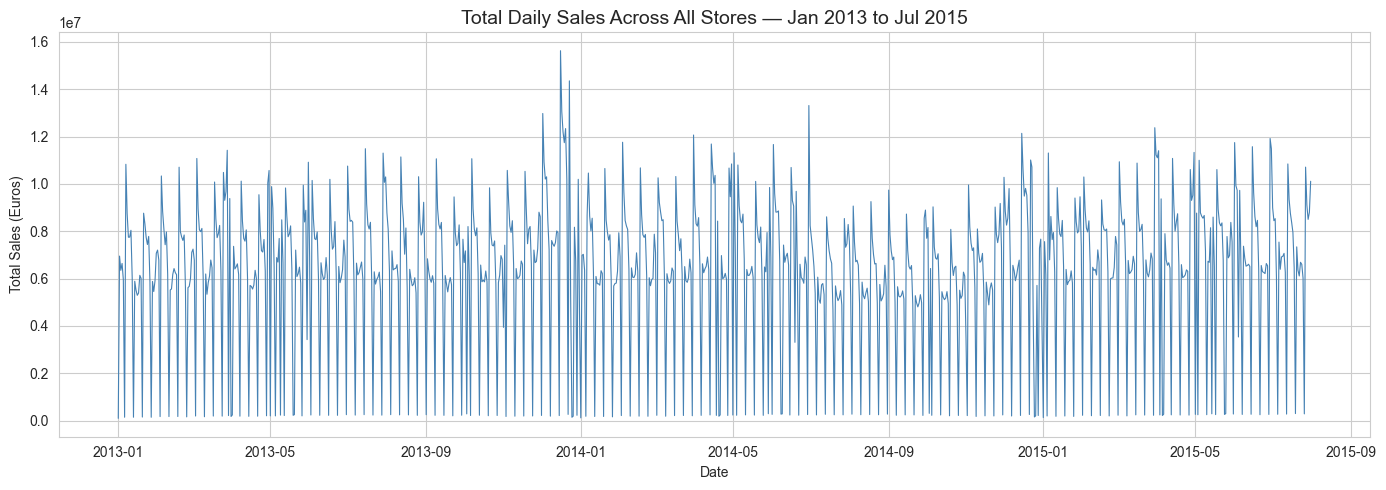

Chart saved!


In [10]:
daily_sales = df.groupby('Date')['Sales'].sum().reset_index()

plt.figure(figsize=(14, 5))
plt.plot(daily_sales['Date'], daily_sales['Sales'], color='steelblue', linewidth=0.8)
plt.title('Total Daily Sales Across All Stores — Jan 2013 to Jul 2015', fontsize=14)
plt.xlabel('Date')
plt.ylabel('Total Sales (Euros)')
plt.tight_layout()
plt.savefig('../outputs/01_sales_over_time.png', dpi=150)
plt.show()
print("Chart saved!")

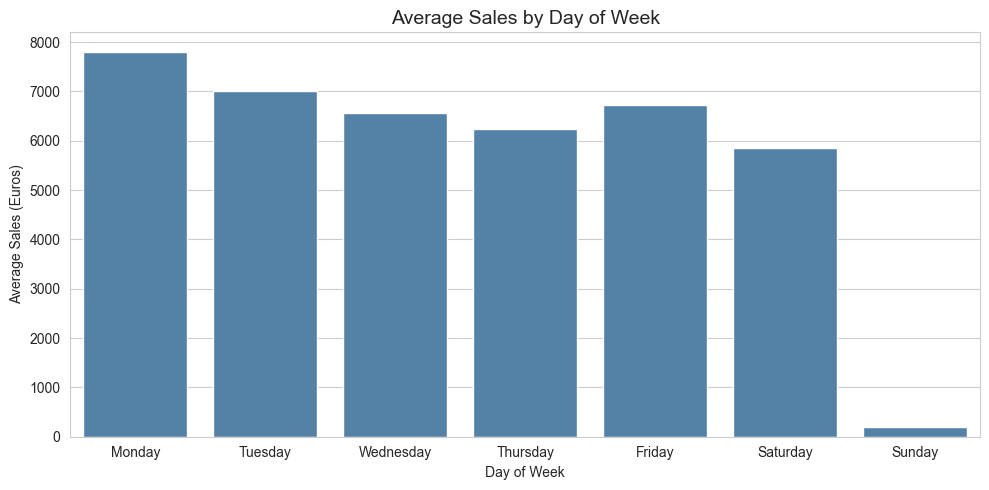

Chart saved!


In [11]:
day_labels = {1: 'Monday', 2: 'Tuesday', 3: 'Wednesday', 
              4: 'Thursday', 5: 'Friday', 6: 'Saturday', 7: 'Sunday'}

day_sales = df.groupby('DayOfWeek')['Sales'].mean().reset_index()
day_sales['DayName'] = day_sales['DayOfWeek'].map(day_labels)

plt.figure(figsize=(10, 5))
sns.barplot(data=day_sales, x='DayName', y='Sales', color='steelblue')
plt.title('Average Sales by Day of Week', fontsize=14)
plt.xlabel('Day of Week')
plt.ylabel('Average Sales (Euros)')
plt.tight_layout()
plt.savefig('../outputs/02_sales_by_day.png', dpi=150)
plt.show()
print("Chart saved!")

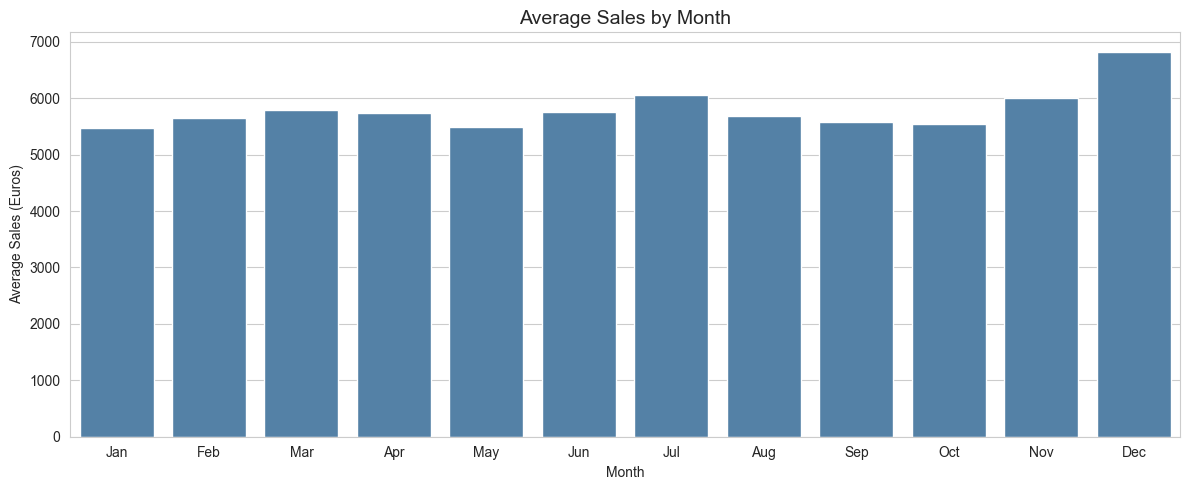

Chart saved!


In [12]:
df['Month'] = df['Date'].dt.month
month_labels = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'May', 6:'Jun',
                7:'Jul', 8:'Aug', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dec'}

month_sales = df.groupby('Month')['Sales'].mean().reset_index()
month_sales['MonthName'] = month_sales['Month'].map(month_labels)

plt.figure(figsize=(12, 5))
sns.barplot(data=month_sales, x='MonthName', y='Sales', color='steelblue')
plt.title('Average Sales by Month', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Average Sales (Euros)')
plt.tight_layout()
plt.savefig('../outputs/03_sales_by_month.png', dpi=150)
plt.show()
print("Chart saved!")

C:\Users\USER-PC\AppData\Local\Temp\ipykernel_4212\4074623820.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=promo_sales, x='PromoLabel', y='Sales',


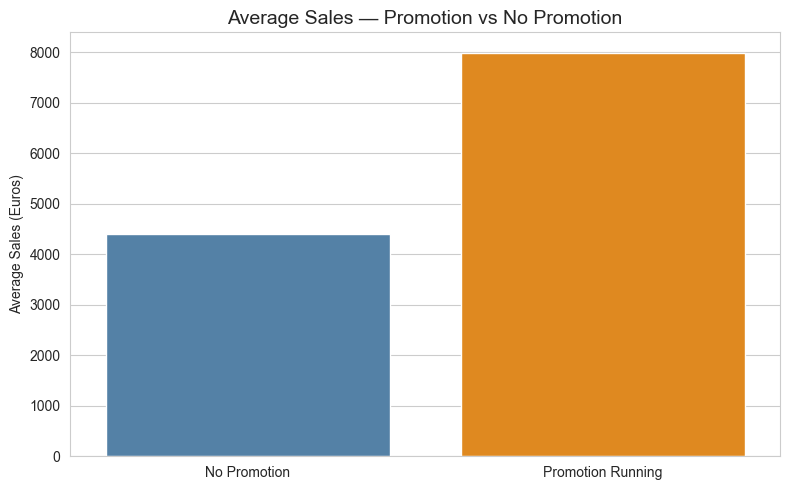

Chart saved!


In [13]:
promo_sales = df.groupby('Promo')['Sales'].mean().reset_index()
promo_sales['PromoLabel'] = promo_sales['Promo'].map({0: 'No Promotion', 1: 'Promotion Running'})

plt.figure(figsize=(8, 5))
sns.barplot(data=promo_sales, x='PromoLabel', y='Sales', 
            palette=['steelblue', 'darkorange'])
plt.title('Average Sales — Promotion vs No Promotion', fontsize=14)
plt.xlabel('')
plt.ylabel('Average Sales (Euros)')
plt.tight_layout()
plt.savefig('../outputs/04_promo_effect.png', dpi=150)
plt.show()
print("Chart saved!")

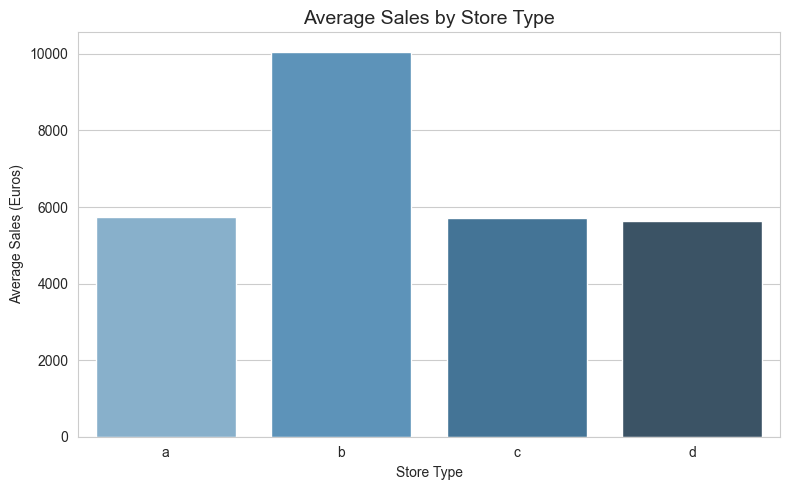

Chart saved!


In [14]:
store_sales = df.groupby('StoreType')['Sales'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(data=store_sales, x='StoreType', y='Sales', 
            hue='StoreType', palette='Blues_d', legend=False)
plt.title('Average Sales by Store Type', fontsize=14)
plt.xlabel('Store Type')
plt.ylabel('Average Sales (Euros)')
plt.tight_layout()
plt.savefig('../outputs/05_sales_by_storetype.png', dpi=150)
plt.show()
print("Chart saved!")

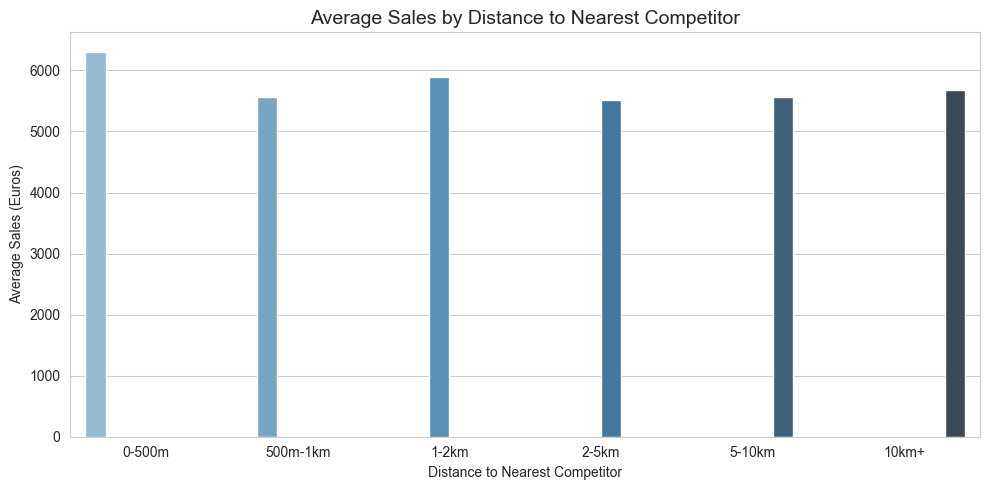

Chart saved!


In [15]:
df['DistanceBucket'] = pd.cut(df['CompetitionDistance'], 
                               bins=[0, 500, 1000, 2000, 5000, 10000, 80000],
                               labels=['0-500m', '500m-1km', '1-2km', '2-5km', '5-10km', '10km+'])

distance_sales = df.groupby('DistanceBucket', observed=True)['Sales'].mean().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(data=distance_sales, x='DistanceBucket', y='Sales',
            hue='DistanceBucket', palette='Blues_d', legend=False)
plt.title('Average Sales by Distance to Nearest Competitor', fontsize=14)
plt.xlabel('Distance to Nearest Competitor')
plt.ylabel('Average Sales (Euros)')
plt.tight_layout()
plt.savefig('../outputs/06_competition_distance.png', dpi=150)
plt.show()
print("Chart saved!")

In [16]:
print("=" * 50)
print("EDA COMPLETE — KEY FINDINGS SUMMARY")
print("=" * 50)
print(f"Total records analysed: {len(df):,}")
print(f"Date range: {df['Date'].min().date()} to {df['Date'].max().date()}")
print(f"Number of stores: {df['Store'].nunique()}")
print(f"Average daily sales (all stores): €{df['Sales'].mean():,.0f}")
print(f"Average sales WITH promotion: €{df[df['Promo']==1]['Sales'].mean():,.0f}")
print(f"Average sales WITHOUT promotion: €{df[df['Promo']==0]['Sales'].mean():,.0f}")
print(f"Busiest day: Monday (avg €{df[df['DayOfWeek']==1]['Sales'].mean():,.0f})")
print(f"Quietest day: Sunday (avg €{df[df['DayOfWeek']==7]['Sales'].mean():,.0f})")
print(f"Best store type: b (avg €{df[df['StoreType']=='b']['Sales'].mean():,.0f})")
print("=" * 50)

EDA COMPLETE — KEY FINDINGS SUMMARY
Total records analysed: 1,017,155
Date range: 2013-01-01 to 2015-07-31
Number of stores: 1115
Average daily sales (all stores): €5,774
Average sales WITH promotion: €7,992
Average sales WITHOUT promotion: €4,406
Busiest day: Monday (avg €7,809)
Quietest day: Sunday (avg €204)
Best store type: b (avg €10,061)
